# Q-Ripple: can network structure help identify illicit transactions?

A transaction's attributes describe the transaction itself. Connections may supply additional evidence, but useful graph information does not automatically imply a useful quantum model.

We investigate four research questions, using each result to motivate the next experiment:

1. How well can transaction attributes classify illicit activity? Does the supplied aggregate feature set add value beyond local attributes?
2. Does known-risk propagation provide additional predictive information?
3. Which numerical descriptions of connectivity help, and does a quantum kernel on those same descriptions improve the classifier?
4. Can a circuit that receives graph connectivity directly produce a useful topology-sensitive representation?

The last question concerns an encoding and its inductive bias, not a claim that topology cannot be represented classically. Classical adjacency, spectral and graph-kernel controls remain essential. The notebook exposes the experimental steps; reusable Python classes perform the repeated computations. Full result tables and plotted matrices are saved in `results/experiment_flow/`.

## What counts as a fair comparison?

**Inputs.** Local means the 93 transaction attributes. All means 165 attributes, including 72 supplied neighborhood aggregates; All is therefore not a purely local baseline. Every hybrid classifier retains its complete Local/All input vector unchanged, alongside its added representation. Nyström coordinates and finite quantum registers do not replace those raw inputs.

**Evaluation.** Train on time steps 1–30, select on 31–34 and evaluate on 35–49. Each of three sampling seeds supplies the same 80/60/100 train/validation/test roots to every simulator stage. Preprocessing and landmarks are fitted on training data only. These are small exploratory cohorts, not a full-dataset benchmark.

**Graph setting.** Graph methods retain unknown-label nodes and reveal a fixed 20% of period-local illicit labels as known seeds. Seeds are excluded from evaluation in every stage. Propagation consequently tests seed-assisted discovery using additional known-risk evidence. A period's full connectivity is assumed available; this is not an online edge-arrival evaluation.

**Selection.** Mean validation AP across sampling seeds selects configurations. Each subsection displays the best classical model, the best quantum model, and that quantum model's exact classical counterpart. The counterpart shares roots, input information, preprocessing, landmarks and RF readout settings. Full sweeps remain available as CSVs and heatmaps. Test scores do not select the displayed winners. Repeated exploration still requires a fresh final holdout before claiming generalisation.

**Reproducibility.** The default `REUSE_SAVED_RESULTS=True` restores the completed simulator fits when saved settings match; the output states when results are reused. Set it to `False` to rerun all fits and depth sweeps. Reports and heatmaps are regenerated from those results. Changing experiment settings forces a rerun; changes to model implementation also require setting reuse to `False`.

## Metrics: what each score measures

The positive class is **illicit**. Let TP, FP, TN and FN denote true/false positives and negatives. Every classification table uses the same five test metrics, with higher values better:

| Metric | Definition | Why report it? |
|---|---|---|
| Accuracy | $(TP+TN)/(TP+TN+FP+FN)$ | Overall correctness; can look high when most transactions are licit. |
| Balanced accuracy | $\tfrac12[TP/(TP+FN)+TN/(TN+FP)]$ | Weights illicit recall and licit recall equally, exposing majority-class shortcuts. |
| Illicit F1 | $2TP/(2TP+FP+FN)$ | Balances illicit precision and recall at the classifier's decision threshold. |
| PR-AUC (AP) | $\sum_k(R_k-R_{k-1})P_k$ over score thresholds | Average precision evaluates illicit ranking. Its random-ranking reference is approximately the illicit fraction. |
| ROC-AUC | Probability that a random illicit case outranks a random licit case, with ties half-weighted | Measures ranking across both classes; may look strong despite weak precision under imbalance. |

“PR-AUC” in this project means scikit-learn **average precision**, not trapezoidal integration of a PR curve. AP and ROC-AUC use probabilities/ranking scores; accuracy, balanced accuracy and F1 use predicted classes (RF's usual decision rule). Validation AP is a selection score, not an additional test metric.

AP depends on prevalence: compare matched simulator cohorts, and report the small balanced hardware pilot separately. AP SD and plot error bars describe variation over three sampling seeds, **not** confidence intervals or shot uncertainty. Similarity, relabeling error and observable noise are diagnostics, so classification accuracy is not meaningful for those tables.

Metric heatmaps share a 0–1 color scale. Configuration heatmaps use an explicitly labelled focused validation-AP scale; gray means an unevaluated combination. Line plots fit the observed values and error bars rather than forcing a 0–1 y-axis.

Definitions: [scikit-learn classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics), [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).

In [1]:
from pathlib import Path
import sys
ROOT = next(p.resolve() for p in [Path.cwd(), Path.cwd() / 'q-ripple-experiements']
            if (p / 'elliptic_models').is_dir())
sys.path.insert(0, str(ROOT))
from elliptic_models import ExperimentFlow

REUSE_SAVED_RESULTS = True  # False reruns all simulator fits and sweeps.
HOPS = (1, 2, 3, 4, 6, 8)
HAMILTONIAN_STEPS = (1, 2, 4, 8)
MESSAGE_LAYERS = (1, 2, 3, 4)
HARDWARE = dict(attributes=False, propagation=False,
                topology_features=False, quantum_topology=True)
flow = ExperimentFlow(ROOT, seeds=(42, 43, 44),
    sizes=dict(train=80, val=60, test=100), hops=HOPS,
    circuit_depths=HAMILTONIAN_STEPS, message_layers=MESSAGE_LAYERS).prepare()

Simulator cohorts ready: {'train': 80, 'val': 60, 'test': 100}; 3 sampling seeds. All four stages share roots.
Full and selected tables: /Users/gigileung/git-qiskit/qiskit_fall_fest_warsaw/q-ripple-experiements/results/experiment_flow


## 1. What do the attributes tell us?

First establish Local 93 and All 165 references without adding any new graph signals. A raw Random Forest (RF) tests what the supplied attributes already explain.

For the kernel arms, train-only standardisation followed by $2\arctan(x)$ produces rotation angles without PCA. An RBF kernel measures numerical proximity, $K(x,x')=\exp[-\gamma\|x-x'\|^2]$. A quantum feature map instead prepares $|\phi(x)\rangle$ and uses fidelity $K_Q(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$.

**Two distinct techniques.** Data re-uploading feeds all attributes through successive rotations on four qubits; one or two passes change the circuit representation. Nyström uses 12 fixed training landmarks to approximate a kernel through coordinates $\Phi(x)=K(x,L)K(L,L)^{\dagger/2}$, retaining the positive eigenspace. It reduces kernel evaluation cost; it does not add information. Both RBF and quantum arms here use the same Nyström/readout arrangement, so their comparison isolates kernel choice. This section's pass sweep is conditional on Nyström; the reusable `ClassificationExperiment` in `elliptic_models/experiments.py` also supports exact-kernel versus Nyström ablations.

**Visible steps:** fit transforms on train → compute matched landmark coordinates → append coordinates to the unchanged raw vector → fit the same RF → select by validation AP → report all five test metrics. The quantum maps are simulated exactly at this stage.

In [2]:
flow.run('Attributes', reuse_saved=REUSE_SAVED_RESULTS)
flow.best('Attributes');

Attributes: restored completed simulator fits from 01_attributes_all.csv.


,Features,Selection,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,Local,Best classical + matched classical,RF + RBF attributes,passes=1; Attributes,0.9300,0.8684,0.5606,0.7722,0.8702,0.6251,3,0.1303
1,Local,Best quantum,RF + quantum attributes,passes=1; Attributes,0.9367,0.8404,0.5493,0.7417,0.8653,0.5997,3,0.2357
2,All,Best classical,Raw RF,raw attributes,0.9333,0.8702,0.5423,0.8054,0.8779,0.5912,3,0.1719
3,All,Matched classical,RF + RBF attributes,passes=1; Attributes,0.9567,0.8825,0.6815,0.7905,0.8772,0.5829,3,0.2304
4,All,Best quantum,RF + quantum attributes,passes=1; Attributes,0.9467,0.8772,0.5977,0.7961,0.8716,0.5829,3,0.1608


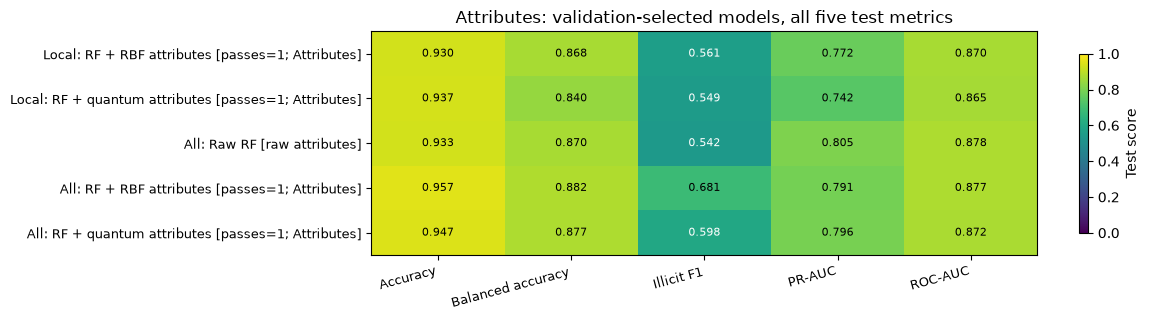

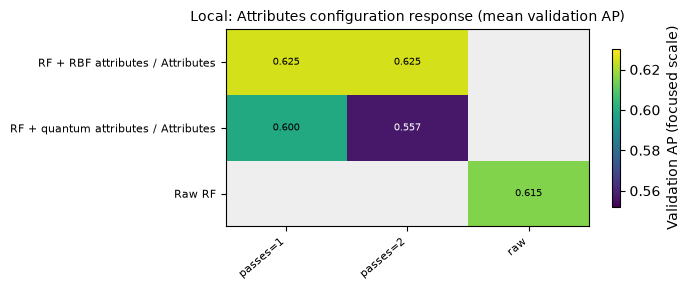

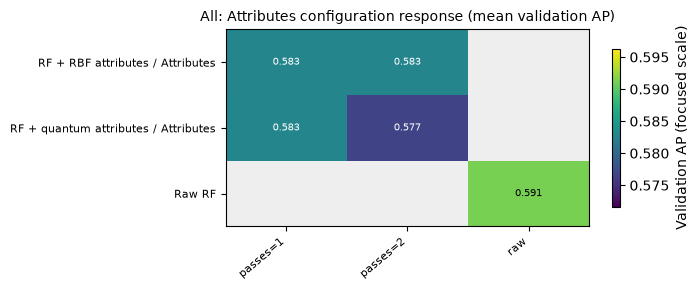

**Local:** the validation-selected classical model has test AP **0.772** (raw RF 0.738; change +0.034). The selected quantum model has AP **0.742**, versus **0.772** for its matched classical kernel (change -0.030).

**All:** the validation-selected classical model has test AP **0.805** (raw RF 0.805; change +0.000). The selected quantum model has AP **0.796**, versus **0.791** for its matched classical kernel (change +0.006).

These are held-out scores after validation selection; they describe this pilot and do not imply a consistent improvement across feature sets.

In [3]:
flow.heatmaps('Attributes')
flow.interpretation('Attributes')

### What question follows from the baseline?

The displayed results establish the reference scores, including any difference between Local and All. A different kernel on the same attributes cannot recover graph information that those attributes omit. We next add known-risk context while retaining every original feature, so any observed gain can be compared with the corresponding raw RF reference.

## 2. Does risk propagation add useful evidence?

A directed edge denotes a transaction connection. At each depth $k$, normalized predecessor and successor walks aggregate seed-risk exposure and degree information. In matrix terms these signals have the form $P^k s$, with $P$ a direction-specific averaging operator and $s$ a known-illicit seed indicator. They measure exposure through **length-$k$ walks**, not exact shortest-path shells; a walk may revisit a node.

The experiment restores the earlier nine propagation descriptors (degrees, neighbor/two-step counts, seed exposure and forward/reverse diffusion), then adds directional profiles through each configured depth. The raw RF is the no-added-context control; legacy RF checks the earlier representation; expanded RF tests the added profiles. Full-period signals are computed before sampling rooted subgraphs, so they are not truncated to the later eight-node circuit budget.

**Kernel controls.** RBF, generic quantum rotations and a hop-aware quantum map receive the same propagation information. The hop-aware circuit groups signals by walk length instead of treating their vector positions as unrelated. Nyström landmarks and the raw-input RF bypass are shared within each pair.

**Visible steps:** compute full-period seed signals → sweep 1/2/3/4/6/8 hops → compare raw/legacy/expanded RF → compare quantum versus matched RBF additions. Radius can increase useful reach or dilute a local signal; the validation heatmaps show which occurs instead of assuming more hops helps.

In [4]:
flow.run('Propagation', reuse_saved=REUSE_SAVED_RESULTS)
flow.best('Propagation');

Propagation: restored completed simulator fits from 02_propagation_all.csv.


,Features,Selection,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,Local,Best classical,RF + legacy propagation,9 legacy features,0.9300,0.8684,0.5390,0.7920,0.8765,0.6545,3,0.1536
1,Local,Matched classical,RF + RBF propagation,hops=4; passes=1; Generic,0.9433,0.8439,0.5556,0.7667,0.8870,0.6313,3,0.1967
2,Local,Best quantum,RF + generic quantum propagation,hops=4; passes=1; Generic,0.9500,0.8789,0.6276,0.7895,0.8828,0.6479,3,0.1982
3,All,Best classical,RF + propagation,hops=6,0.9367,0.8719,0.5652,0.7872,0.8758,0.6357,3,0.1474
4,All,Matched classical,RF + RBF propagation,hops=4; passes=1; Generic,0.9467,0.8772,0.6333,0.7938,0.8940,0.6252,3,0.1502
5,All,Best quantum,RF + generic quantum propagation,hops=4; passes=1; Generic,0.9467,0.8772,0.6333,0.7887,0.8912,0.6192,3,0.1449


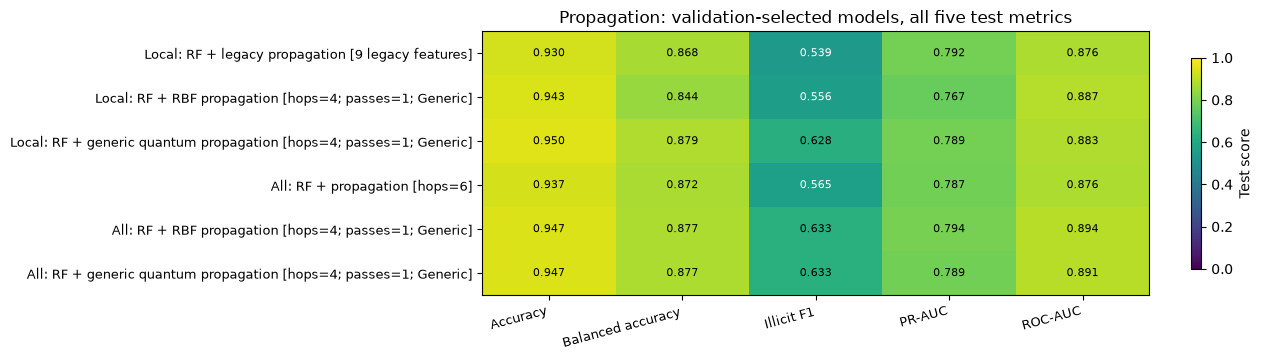

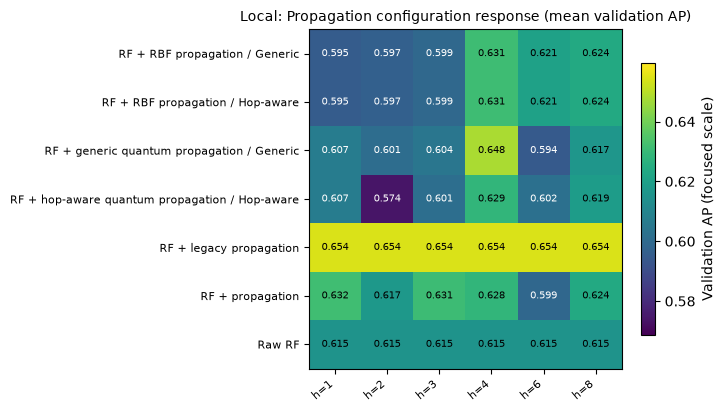

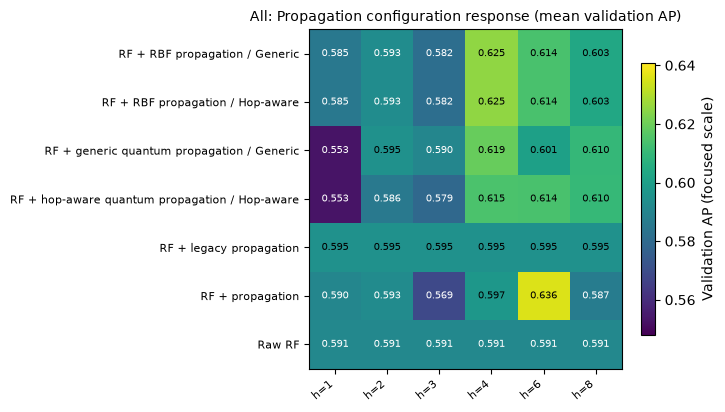

**Local:** the validation-selected classical model has test AP **0.792** (raw RF 0.738; change +0.054). The selected quantum model has AP **0.789**, versus **0.767** for its matched classical kernel (change +0.023).

**All:** the validation-selected classical model has test AP **0.787** (raw RF 0.805; change -0.018). The selected quantum model has AP **0.789**, versus **0.794** for its matched classical kernel (change -0.005).

These are held-out scores after validation selection; they describe this pilot and do not imply a consistent improvement across feature sets.

In [5]:
flow.heatmaps('Propagation')
flow.interpretation('Propagation')

### From exposure to connectivity

Use the preceding raw-RF differences to judge whether propagation helps Local, All, or both. All already contains neighborhood aggregates, so its incremental gain may differ. Quantum-minus-RBF differences answer a separate question about the representation, not whether propagation is useful. Propagation compresses connectivity into exposure signals; next we ask whether structural summaries retain complementary evidence.

## 3. Which numerical topology features help?

Sample a rooted subgraph within each candidate radius using a fixed eight-node budget. The radius determines eligible context; the node budget determines retained capacity. The root and known seeds remain marked. Increasing radius does not guarantee that all reachable nodes fit. Raw attributes and full-period propagation still bypass the sampled branch unchanged.

### Topology features: describe the graph before choosing a kernel

Here, a classical calculation converts the sampled graph $G$ into a numerical vector $s(G)$: for example, triangle counts, degree statistics or spectral values. The classifier's kernel branch then sees this **description of connectivity**, rather than the adjacency matrix itself.

The two descriptor-kernel routes are:

- **Classical:** graph → numerical summaries → RBF similarities → Nyström coordinates → RF.
- **Quantum:** graph → the same numerical summaries → rotation angles in a generic re-uploading circuit → quantum similarities → Nyström coordinates → RF.

The second route uses a quantum feature map, but **graph edges do not determine its gates**. A triangle count becomes an input angle; the three particular edges forming that triangle are not supplied to the circuit. If two graphs have the same chosen summary vector, both of these descriptor kernels must treat them identically. A more expressive circuit cannot recover a distinction already discarded by $s(G)$.

That limitation concerns these particular summaries, not classical computation in general. The rooted WL control below uses graph neighborhoods directly and can retain distinctions that the chosen counts miss.

We compare three classical views of the retained topology:

- **Motifs and walks:** counts, degree statistics, density, triangles and root/seed walk information. These are interpretable summaries but many distinct graphs share them.
- **Spectra:** those summaries plus undirected adjacency eigenvalues, directed adjacency singular values and root return-walk counts. These probe global connectivity but are not a complete graph invariant.
- **Rooted Weisfeiler–Lehman (WL):** iteratively refine node labels from neighbor labels, then compare label-count features. This provides a graph-structured classical control beyond hand-chosen scalar counts.

RFs test unencoded descriptors. Matched RBF and re-uploading quantum kernels test the **same motif/spectral vectors**, with the same landmarks and raw-input RF branch. No node attributes enter this topology branch; the root's full Local/All attributes remain in the bypass.

**Visible steps:** sample identical subgraphs → calculate numerical descriptions → fit train-only transforms → compare descriptor RF, WL, RBF and quantum kernels → select radius/descriptor using validation AP. If descriptors help but a quantum kernel on them does not, that motivates testing an encoding of connectivity itself; it does not prove any classical limitation.

In [6]:
flow.run('Topology features', reuse_saved=REUSE_SAVED_RESULTS)
flow.best('Topology features');

Topology features: restored completed simulator fits from 03_topology_features_all.csv.


,Features,Selection,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,Local,Best classical,RF + RBF topology features,hops=1; passes=2; Motifs,0.9267,0.8667,0.5310,0.7906,0.8716,0.6456,3,0.1534
1,Local,Matched classical,RF + RBF topology features,hops=1; passes=2; Spectra,0.9300,0.8684,0.5457,0.7911,0.8779,0.6389,3,0.1523
2,Local,Best quantum,RF + quantum topology features,hops=1; passes=2; Spectra,0.9267,0.8667,0.5310,0.7834,0.8800,0.6475,3,0.1416
3,All,Best classical,RF + spectra,hops=6; passes=2; Spectra,0.9433,0.8754,0.5825,0.7705,0.8765,0.6449,3,0.1749
4,All,Matched classical,RF + RBF topology features,hops=3; passes=2; Spectra,0.9233,0.8649,0.5110,0.7622,0.8912,0.6386,3,0.1898
5,All,Best quantum,RF + quantum topology features,hops=3; passes=2; Spectra,0.9367,0.8719,0.5717,0.7847,0.8891,0.6213,3,0.2392


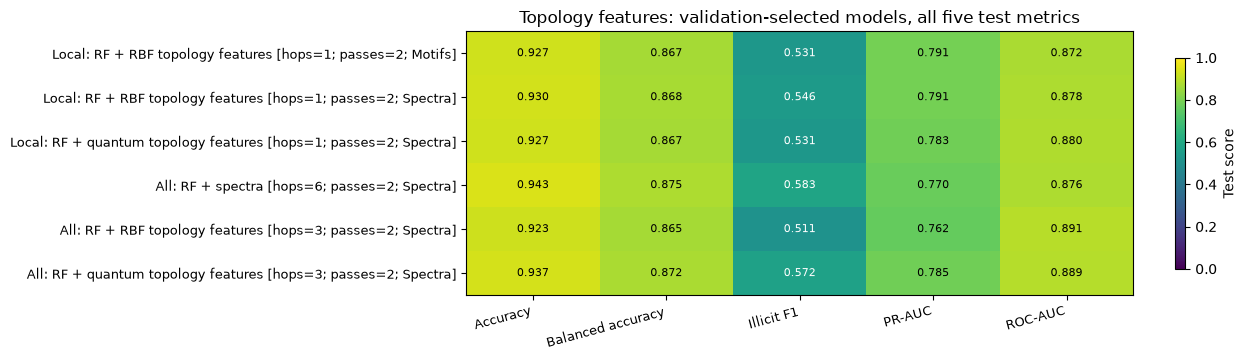

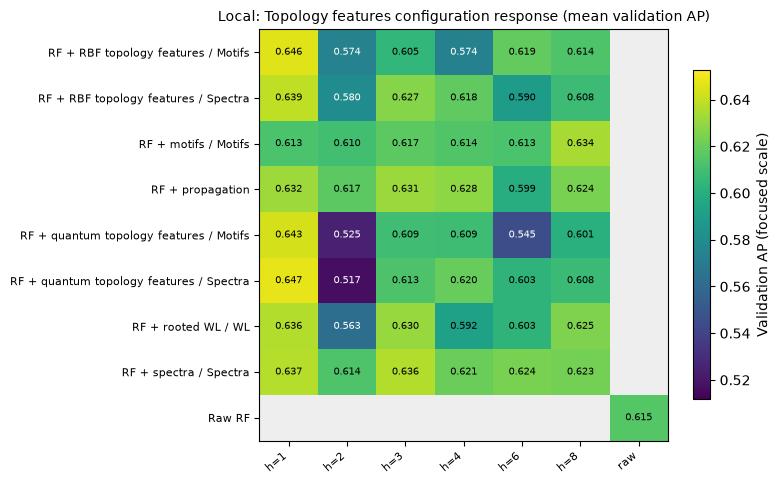

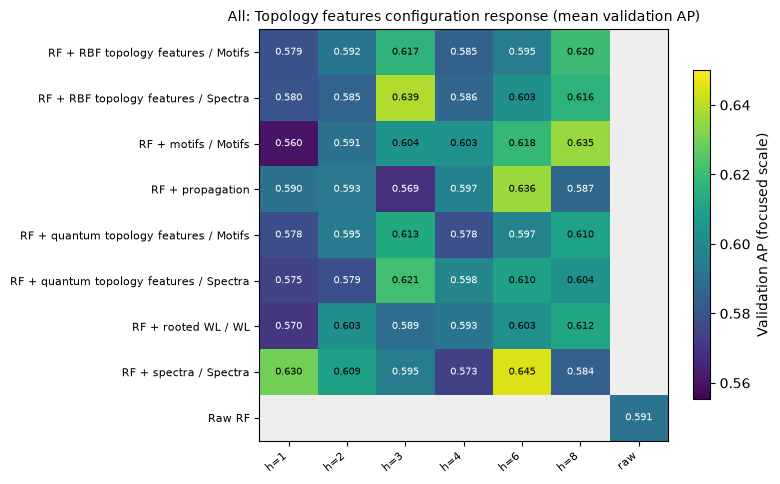

**Local:** the validation-selected classical model has test AP **0.791** (raw RF 0.738; change +0.052). The selected quantum model has AP **0.783**, versus **0.791** for its matched classical kernel (change -0.008).

**All:** the validation-selected classical model has test AP **0.770** (raw RF 0.805; change -0.035). The selected quantum model has AP **0.785**, versus **0.762** for its matched classical kernel (change +0.023).

These are held-out scores after validation selection; they describe this pilot and do not imply a consistent improvement across feature sets.

In [7]:
flow.heatmaps('Topology features')
flow.interpretation('Topology features')

## 4. Can a circuit use connectivity directly?

A quantum circuit receiving only a summary vector cannot distinguish graphs that collide under that summary. Direct graph encoding changes the input representation: actual adjacency and root/seed markers determine the circuit. Classical adjacency RBF and WL remain relevant controls because connectivity is also representable classically.

### Direct quantum topology: let connectivity determine the circuit

Here we bypass the motif/spectral summary step in the topology branch. The retained adjacency matrix $A$, active-node mask, root marker and known-seed markers are supplied to a graph-dependent encoder. For the Hamiltonian encoder, an observed directed edge $i\rightarrow j$ adds an interaction $Z_iX_j$; changing which nodes are connected changes the circuit's interactions. In the message encoder, edges similarly determine which node pairs interact. The Hermitian-walk control builds its evolution operator from adjacency.

The route is **graph connectivity → graph-dependent quantum state or observables → similarities → Nyström coordinates → RF**. “Direct” describes where the graph enters the encoder. It does not mean the final classifier is entirely quantum, that the encoding preserves every graph distinction, or that the circuit necessarily runs on hardware. These experiments first simulate the quantum circuits; only the final hardware section measures them on IBM devices.

| Comparison | Topology information supplied to the kernel | How similarities are constructed |
|---|---|---|
| Numerical topology + RBF | Chosen motif/spectral vector $s(G)$ | RBF distance between summary vectors |
| Numerical topology + quantum | The same $s(G)$ | Fidelity after generic angle encoding of those summaries |
| Direct topology + classical control | Packed adjacency, mask, root and seed markers | RBF distance between the packed graph vectors |
| Direct quantum topology | The same packed graph information | Graph-dependent evolution followed by state fidelity or an observable-based kernel |

All four routes append their coordinates to the appropriate **unchanged Local 93 / All 165 attributes plus full-period propagation inputs** before the RF readout. The topology branch in this experiment excludes numerical node attributes. Direct encoding retains explicit edges within the sampled node budget; sampling, finite registers and the final kernel can still lose distinctions. Numerical summaries can also be useful because they deliberately ignore irrelevant differences in node ordering.

### Why is there still a classical comparison?

A quantum encoding does not make the underlying graph unavailable to classical models. For every direct quantum run, **`RF + adjacency RBF`** receives the exact same retained graph, represented as

$$x_G=[\mathrm{mask},\mathrm{root},\mathrm{seeds},0,\mathrm{vec}(A)].$$

The zero block is the unused node-attribute-angle block in the shared input format. The classical control computes

$$K_C(G,G')=\exp[-\gamma\|x_G-x_{G'}\|^2],$$

while the fidelity encoders compute

$$K_Q(G,G')=|\langle\psi_G|\psi_{G'}\rangle|^2.$$

The Hamiltonian-moment variant instead computes an RBF kernel between quantum observable vectors. Its listed classical counterpart remains adjacency RBF, so that comparison includes a change in readout as well as encoding. It is not a comparison against a classically computed version of the same moments.

Within each pair, we hold fixed the sampled roots and graph ordering, hop radius, retained-node budget, known seeds, train/validation/test splits, landmark indices, raw-input bypass and RF settings. Only the way the topology branch constructs similarities changes. Both sets of similarities go through the same Nyström procedure. **Quantum minus matched classical** therefore asks whether this quantum-derived representation helps this hybrid classifier relative to this adjacency-RBF baseline.

The classical control has no circuit depth. Its score is repeated alongside each quantum step/layer setting because it is the same reference at that radius; those repetitions are not additional classical fits with deeper circuits. The earlier WL and spectral controls provide further classical context, but the explicitly matched row for these direct runs is adjacency RBF.

This is a controlled representation comparison, not an assertion that the classical control reproduces the quantum function, the best possible classical graph model, or proof of a computational advantage. Classical statevector simulation of $K_Q$ is still labelled a **quantum model** because its feature map is defined by a quantum circuit; **classical baseline** refers to $K_C$, and **hardware execution** refers to evaluating quantum circuits on the device.

### First check: is the encoding sensitive to the right differences?

The eight-node cube and Möbius-ladder probe share the selected degree, triangle and walk summaries but have different connectivity. We test their similarity alongside relabeled copies. A useful representation should separate structurally different graphs while treating an isomorphic relabeling consistently. Spectral and WL controls check whether the distinction is already accessible classically.

Fidelity between ordered register states can depend on node ordering. Deterministic sampling order is not a canonical graph labeling. Invariant observable summaries address the readout differently; finite ordered product formulas can still introduce relabeling error. The table reports similarity and relabeling diagnostics, not classification scores, and cannot establish quantum advantage.

In [8]:
flow.structural_check()

,Encoder,Different graph similarity,Isomorphic mean similarity,Mean relabeling error
11,Classical summary RBF,1.0000,1.0000,0.0000
12,Classical spectral RBF,0.6179,1.0000,0.0000
13,Quantum summary rotations,1.0000,1.0000,0.0000
19,Quantum Hamiltonian invariant moments (product),0.9735,0.9996,0.0004
21,Classical rooted WL,0.8577,1.0000,0.0000


### Ordering robustness: retain the earlier diagnostic

The earlier study also compared permutation mixtures and perturbed node orders using metric heatmaps. We retain that plot here because ordering sensitivity can masquerade as a topology effect. These are **archived runs on different cohorts/settings**, saved separately and excluded from the current pilot winners and final paired summary. Their five classification metrics have the same definitions.

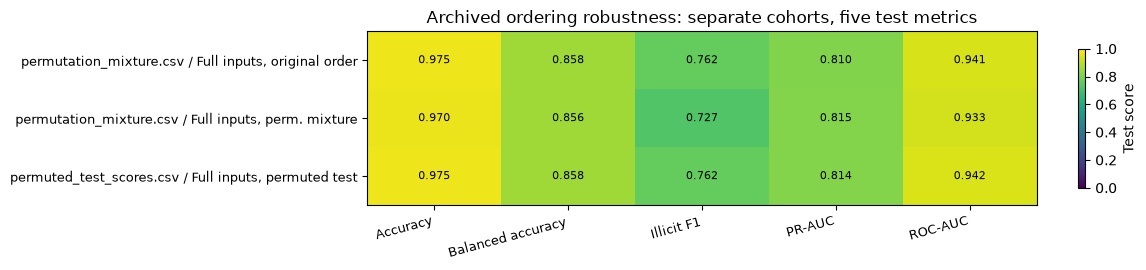

In [9]:
flow.ordering_heatmap()

### Direct encoders and the simulator depth experiment

**Hamiltonian encoding.** Directed edges control noncommuting interactions. The implemented model evolves for fixed $t=0.8$ under

$$H_G=0.37\sum_iY_i+0.7\sum_{i\rightarrow j}Z_iX_j,\qquad |\psi_G(t)\rangle\approx U_r(t)|\psi_{\mathrm{root,seed}}\rangle.$$

A symmetric second-order product formula with $r=1,2,4,8$ steps approximates this evolution. Increasing $r$ primarily tests approximation error and circuit cost at fixed physical time, not a longer propagation time. We test both state fidelity and an RBF kernel on quantum observable moments; the latter changes the readout as well as the representation.

**Message circuit.** Repeated node preparations and edge-controlled ZX interactions encode directed message structure. Sweeping 1–4 layers changes this encoder's hypothesis, unlike refining a fixed-time product formula.

**Hermitian walk.** The directed adjacency matrix $A$ is embedded in $\begin{bmatrix}0&A\A^T&0\end{bmatrix}$ to define unitary dynamics. This is a small-system dense-synthesis control with a different register representation, not ordinary classical diffusion or a demonstrated scalable loading scheme.

**Controlled comparisons.** Sweep radius at a fixed eight-node budget and four Hamiltonian steps. Separately sweep Hamiltonian steps and message layers at fixed four-hop radius. Quantum and adjacency-RBF arms see identical retained adjacency/root/seed information; Local/All attributes and full-period propagation remain unchanged in both RF readouts. Ideal statevector simulation isolates representation effects before device noise. All configurations are saved; stars mark validation-selected depths.

Quantum topology: restored completed simulator fits from 04_quantum_topology_all.csv.


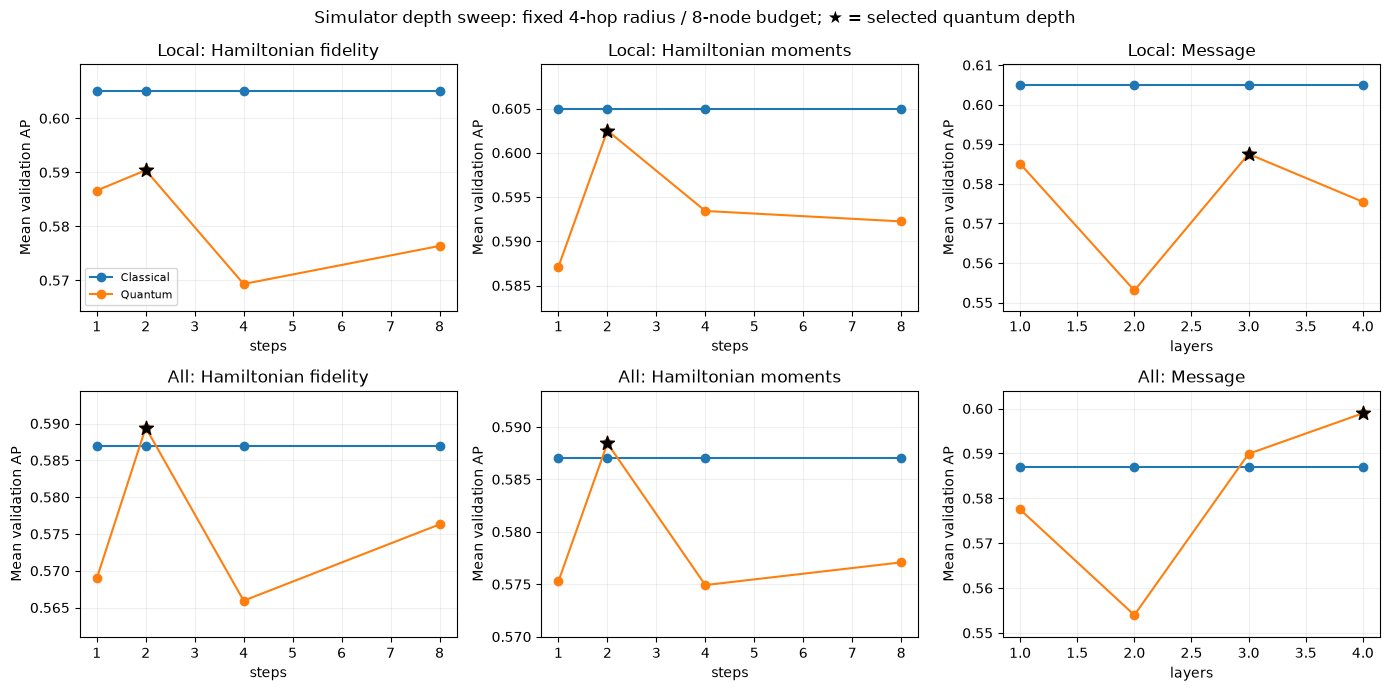

,Features,Selection,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,Local,Best classical + matched classical,RF + adjacency RBF,hops=1; steps=4; Hamiltonian fidelity quantum,0.9267,0.8667,0.5310,0.7916,0.8800,0.6461,3,0.1526
1,Local,Best quantum,RF + Hamiltonian fidelity quantum,hops=1; steps=4,0.9233,0.8649,0.5183,0.7832,0.8751,0.6502,3,0.1428
2,All,Best classical,RF + propagation,hops=6,0.9367,0.8719,0.5652,0.7872,0.8758,0.6357,3,0.1474
3,All,Matched classical,RF + adjacency RBF,hops=8; steps=4; Hamiltonian fidelity quantum,0.9533,0.8491,0.6493,0.7755,0.8730,0.6094,3,0.1332
4,All,Best quantum,RF + Hamiltonian fidelity quantum,hops=8; steps=4,0.9767,0.8614,0.7591,0.7781,0.8800,0.6269,3,0.1349


In [10]:
flow.run('Quantum topology', reuse_saved=REUSE_SAVED_RESULTS)
flow.best('Quantum topology');

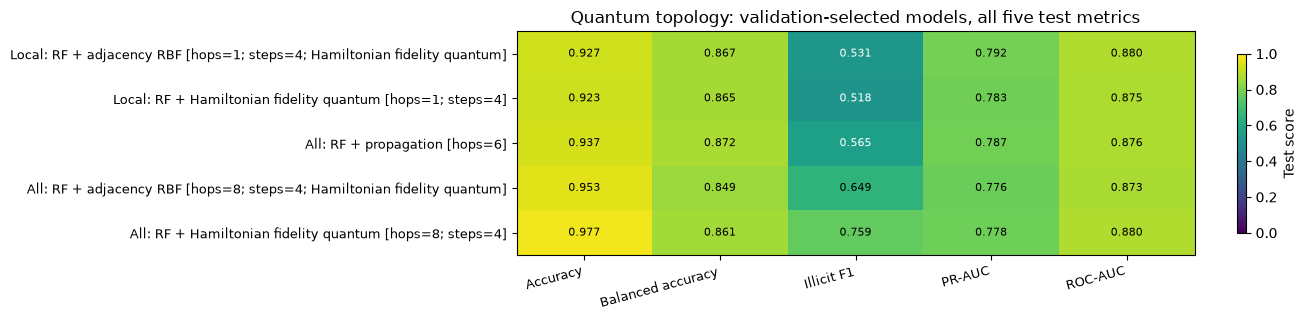

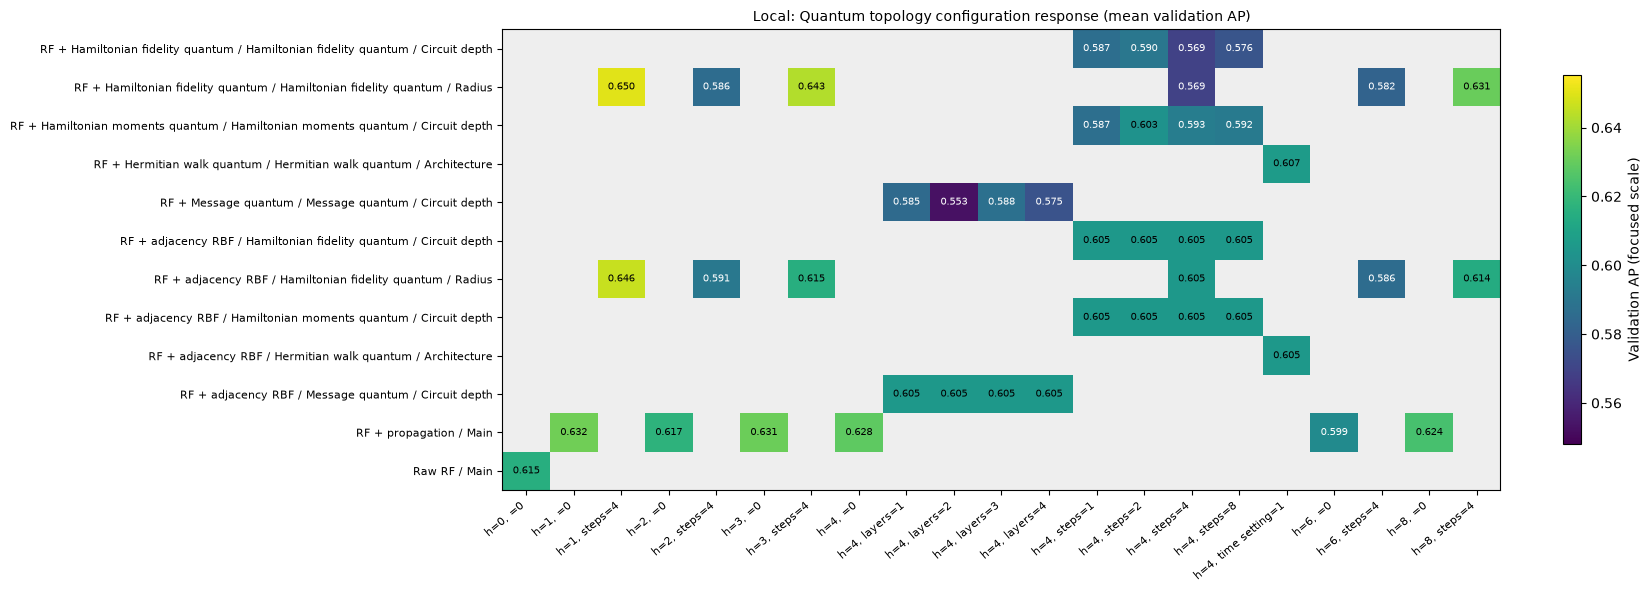

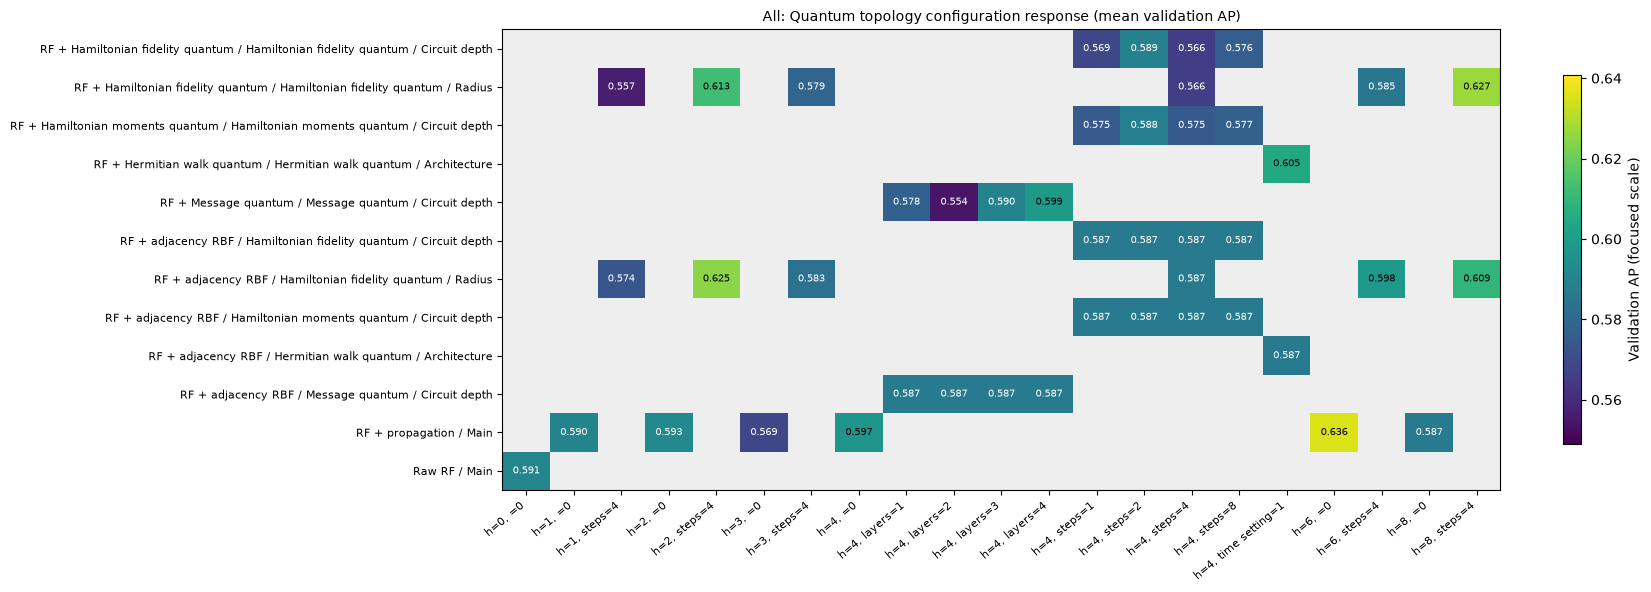

**Local:** the validation-selected classical model has test AP **0.792** (raw RF 0.738; change +0.053). The selected quantum model has AP **0.783**, versus **0.792** for its matched classical kernel (change -0.008).

**All:** the validation-selected classical model has test AP **0.787** (raw RF 0.805; change -0.018). The selected quantum model has AP **0.778**, versus **0.776** for its matched classical kernel (change +0.003).

These are held-out scores after validation selection; they describe this pilot and do not imply a consistent improvement across feature sets.

In [11]:
flow.heatmaps('Quantum topology')
flow.interpretation('Quantum topology')

### Inspect the similarities, not just the final AP

These heatmaps restore the kernel view from the earlier notebooks. Each matrix uses the same first 24 training roots in the same order. Compare RBF versus quantum kernels on spectral summaries, then compare adjacency RBF versus direct Hamiltonian encoding. Brighter entries mean greater similarity, not better classification. A nearly constant or diagonal kernel can suggest an unhelpful representation; visual differences alone do not establish predictive benefit. Kernel matrices and root identities are exported as CSVs.

The spectral pair compares **two kernels after the same classical summary step**. The adjacency/Hamiltonian pair compares **two ways to use explicit graph connectivity**. Read the second pair alongside its matched classification scores: a different-looking quantum similarity matrix is useful only if it improves the downstream task under the shared evaluation protocol.

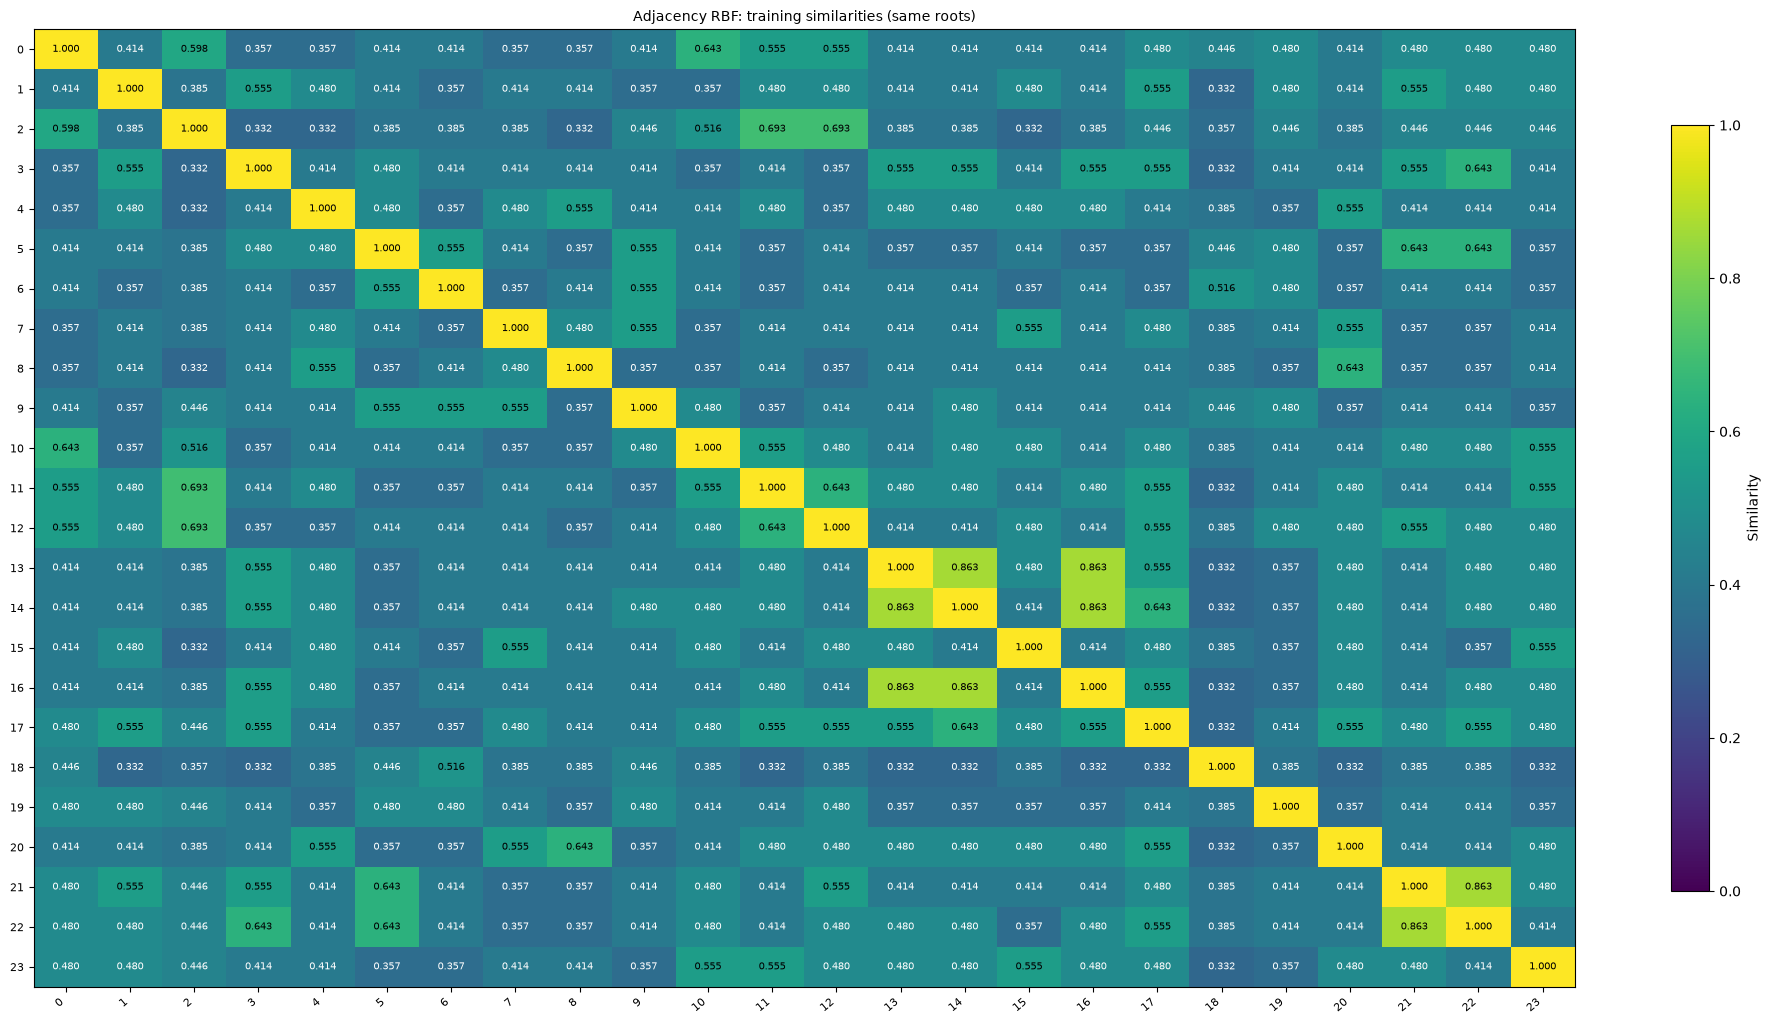

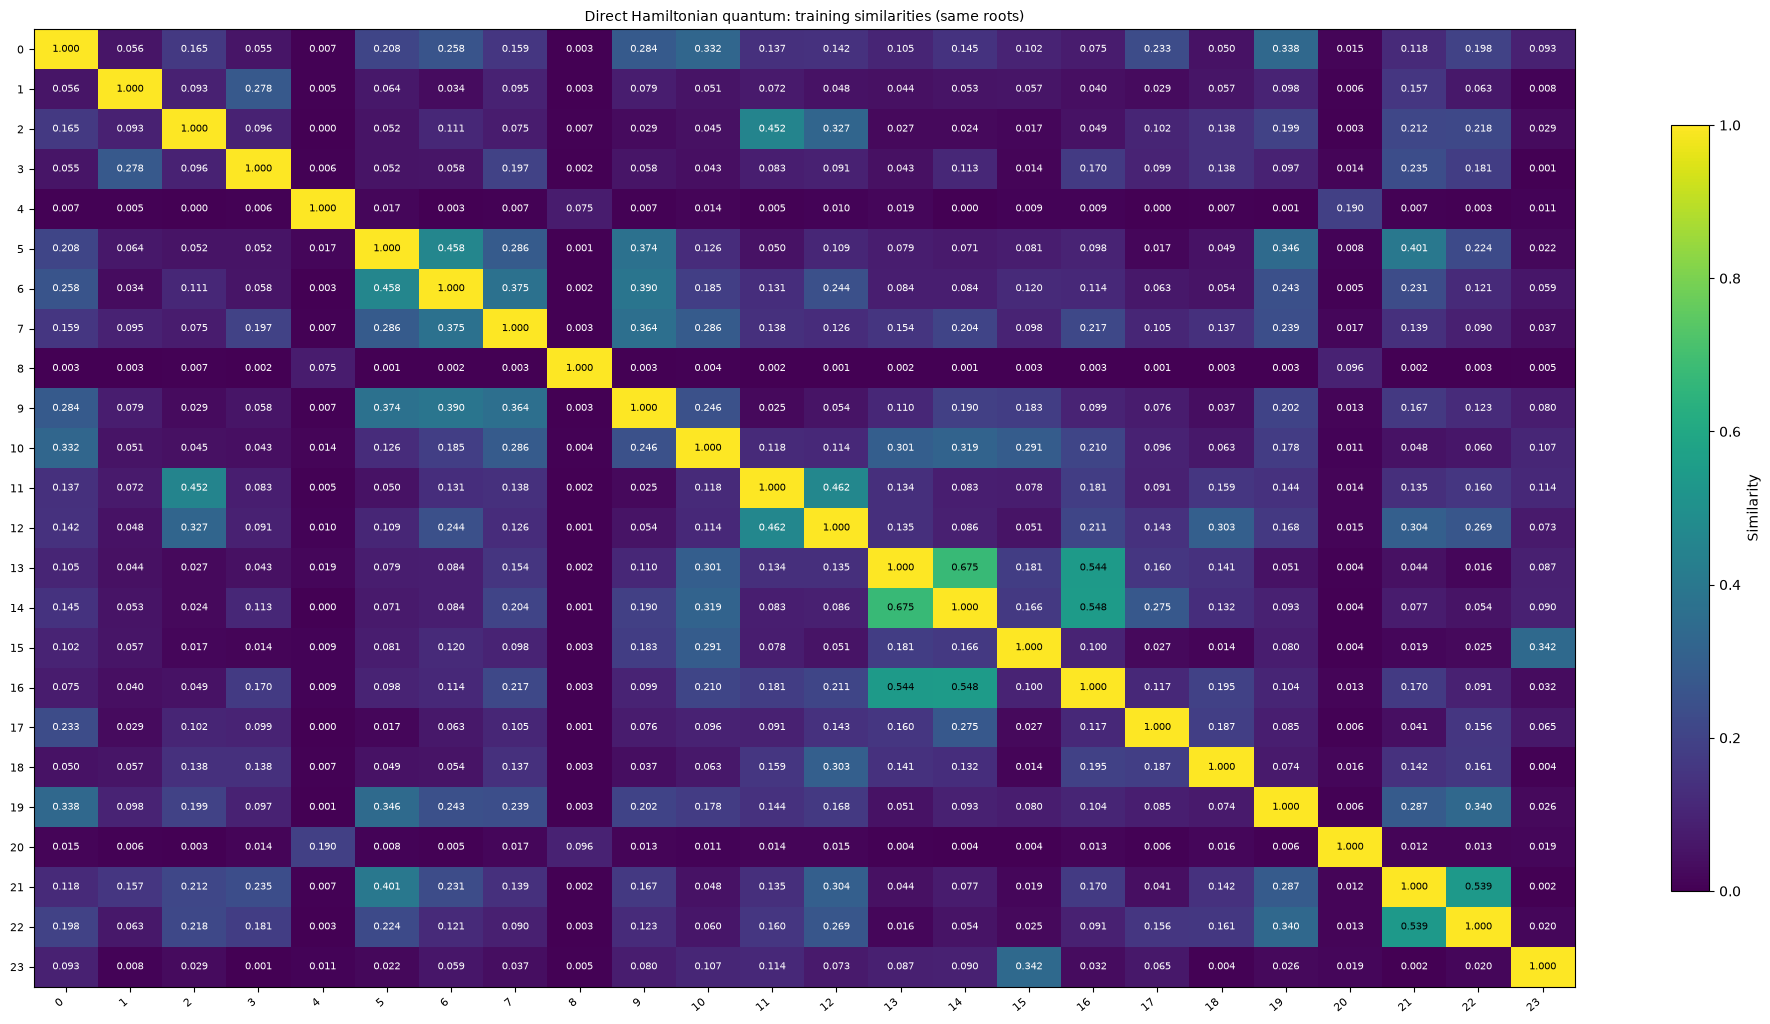

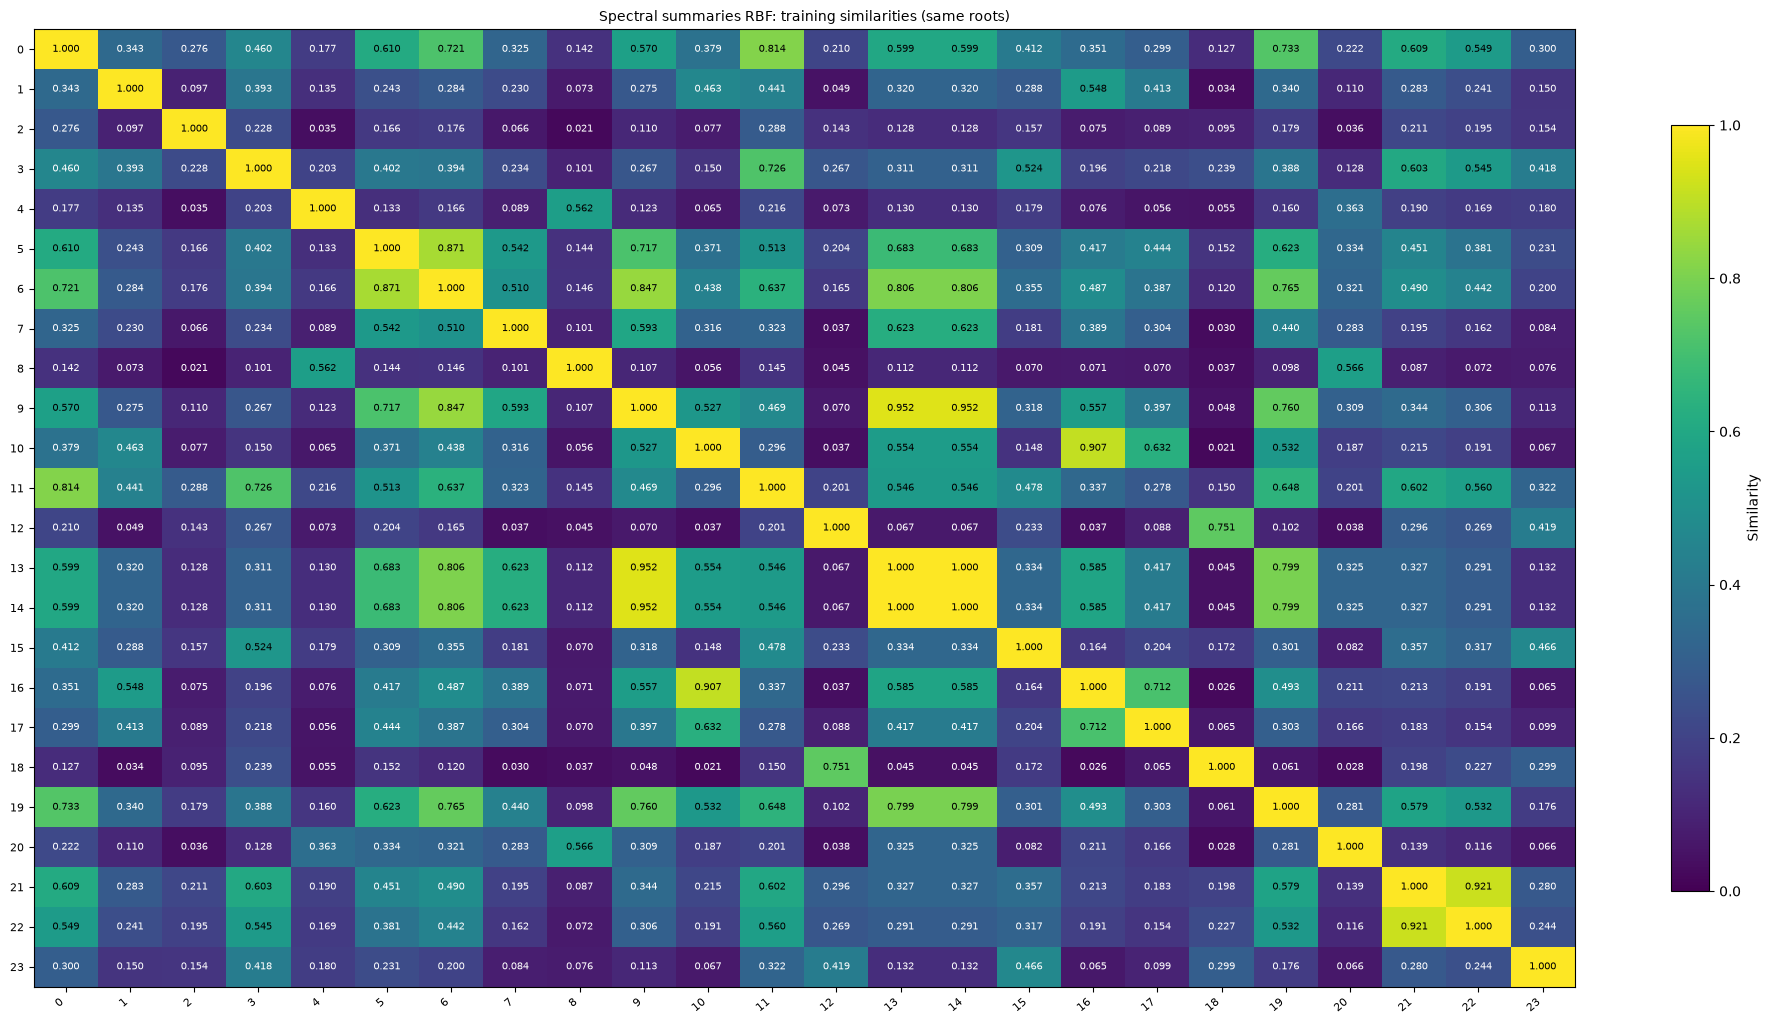

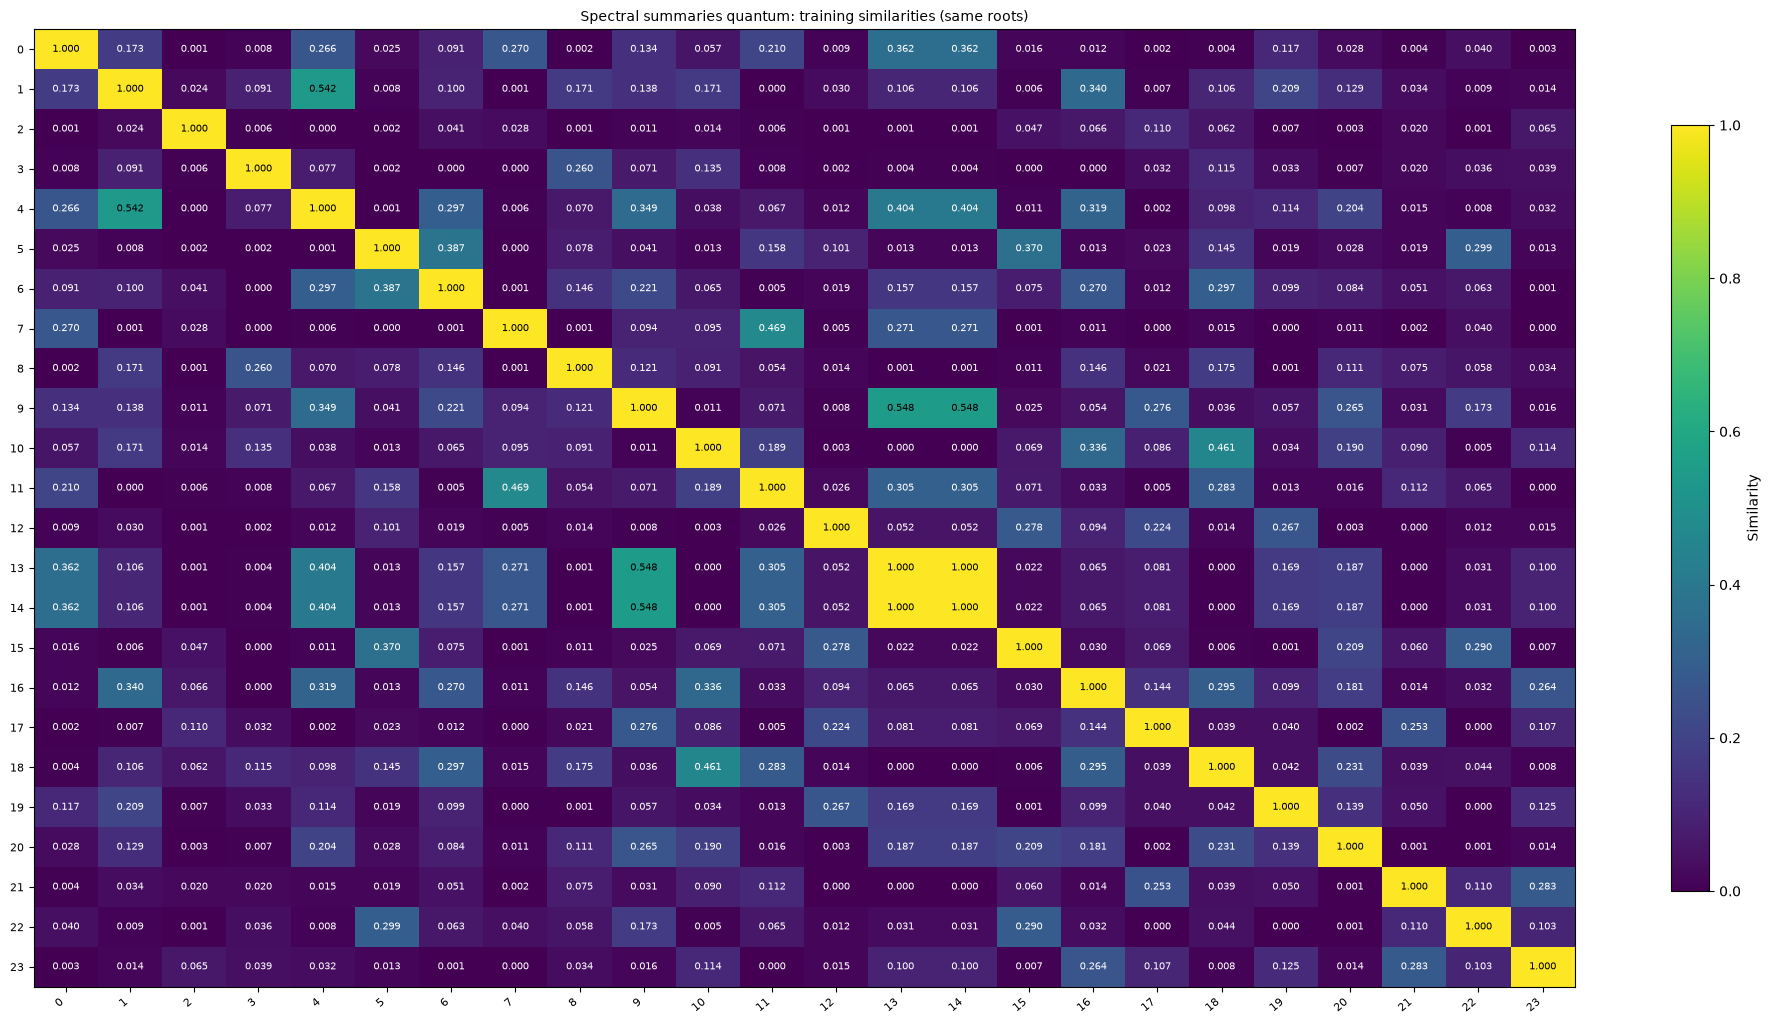

In [12]:
flow.kernel_heatmaps(hops=4, count=24)

## 5. What survives on IBM hardware?

**Most IBM hardware runs are disabled:** attribute, propagation and numerical-topology kernels run on simulators. **Only the final direct quantum-topology experiment is enabled.** This concentrates the physical budget on graph dynamics and measures the practical effects of routing, two-qubit gate depth, shots and device noise after the ideal-encoder comparisons.

The final method recovers the recorded `ibm_fez` jobs; it does not submit duplicates. If those artifacts are absent/incomplete, the enabled method uses the externally saved IBM account and submits only missing groups. Credentials are never embedded here.

The small eight-qubit pilot compares raw+propagation, adjacency RBF, ideal Hamiltonian and measured Hamiltonian on identical balanced 12/8/12 roots and landmarks, with all five metrics. Its different prevalence and tiny test set require separate interpretation. Ideal/measured structural-kernel heatmaps expose noise directly; AP alone is insufficient.

A separate 40-active-qubit experiment tests real subgraphs with directed, reversed and edgeless controls using magnetization, its second moment and root Z. Shot error bars measure sampling uncertainty, not device bias. The edgeless control has an analytic product-state reference; there is no full 40-qubit statevector benchmark and no claim that other classical simulators are infeasible.

,Model,Execution,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC
0,Classical topology RBF,Local,0.6667,0.6667,0.7143,0.8135,0.7639,0.8750
1,Ideal Hamiltonian,Local,0.6667,0.6667,0.7143,0.8135,0.7639,0.8750
2,IBM Hamiltonian,Physical,0.6667,0.6667,0.7143,0.9444,0.9167,0.8750
3,Raw + propagation RF,Local,0.6667,0.6667,0.7143,0.6190,0.5972,0.8125


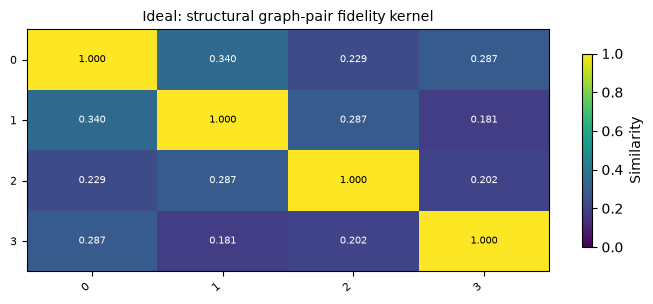

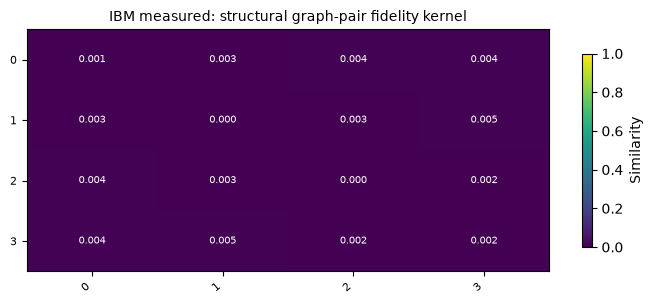

**Final topology hardware enabled:** recovered two completed jobs on **ibm_fez** (52 charged QPU seconds); no duplicate submissions. The 12-case balanced test set is separate from the simulator cohorts. Structural kernel MAE **0.438** indicates strong noise; AP alone is not evidence of a quantum gain.

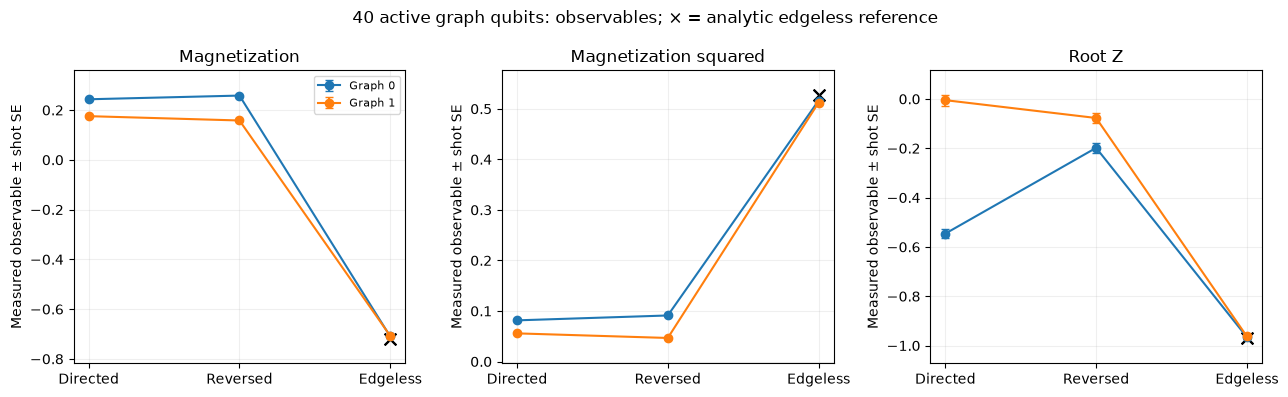

In [13]:
flow.hardware(enabled=HARDWARE['quantum_topology'])

## Final comparison: what have we learned?

Read the evidence in the order tested: attribute baseline; added risk exposure; numerical topology; direct connectivity encoding. The stage observations compare selected classical results with the original raw RF. The table below instead isolates kernel choice: each selected quantum model appears beside its exact classical counterpart, including Local and All. These are distinct questions and should not be conflated.

The first figure tracks the selected classical models against their raw RF references, so any gain from added information is visible separately. These are selected model scores, not a single architecture with only one feature group changed. The heatmap shows every core test metric. The difference plots show quantum minus matched classical for the same selected configuration; zero denotes parity and error bars are sampling SD. A selected winner's AP can improve while balanced accuracy or F1 declines, so consider all five metrics together. Later stages use different representations and multiple explored configurations; they do not constitute a controlled proof of monotonically increasing performance.

The hardware results above answer execution/noise questions on a separate pilot. They do not establish predictive quantum advantage. Full runs, selected tables, paired differences, diagnostic matrices and figure data are indexed in `results/experiment_flow/result_index.csv`; figures are saved as PNG and SVG.

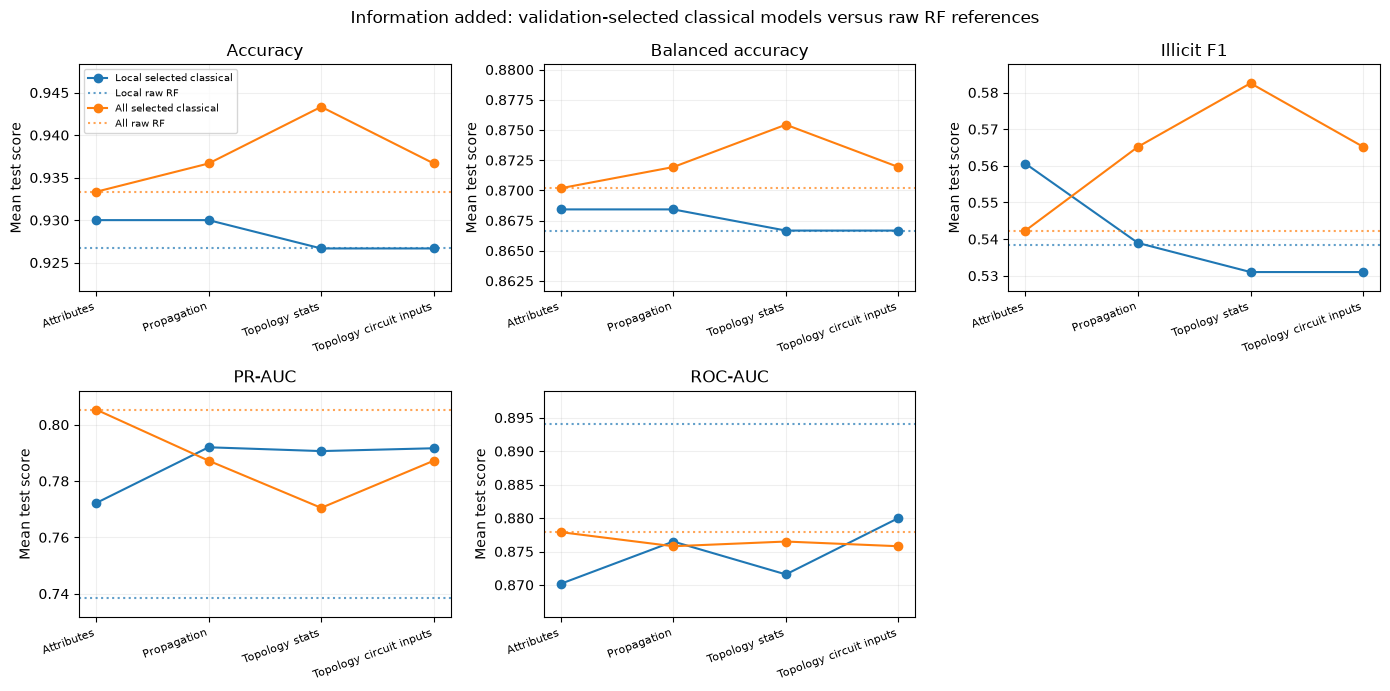

,Stage,Features,Family,Model,Setting,Accuracy,Balanced accuracy,Illicit F1,PR-AUC,ROC-AUC,Validation PR-AUC,Seeds,AP SD
0,Attributes,Local,Classical,RF + RBF attributes,passes=1; Attributes,0.9300,0.8684,0.5606,0.7722,0.8702,0.6251,3,0.1303
1,Attributes,Local,Quantum,RF + quantum attributes,passes=1; Attributes,0.9367,0.8404,0.5493,0.7417,0.8653,0.5997,3,0.2357
2,Attributes,All,Classical,RF + RBF attributes,passes=1; Attributes,0.9567,0.8825,0.6815,0.7905,0.8772,0.5829,3,0.2304
3,Attributes,All,Quantum,RF + quantum attributes,passes=1; Attributes,0.9467,0.8772,0.5977,0.7961,0.8716,0.5829,3,0.1608
4,Propagation,Local,Classical,RF + RBF propagation,hops=4; passes=1; Generic,0.9433,0.8439,0.5556,0.7667,0.8870,0.6313,3,0.1967
5,Propagation,Local,Quantum,RF + generic quantum propagation,hops=4; passes=1; Generic,0.9500,0.8789,0.6276,0.7895,0.8828,0.6479,3,0.1982
6,Propagation,All,Classical,RF + RBF propagation,hops=4; passes=1; Generic,0.9467,0.8772,0.6333,0.7938,0.8940,0.6252,3,0.1502
7,Propagation,All,Quantum,RF + generic quantum propagation,hops=4; passes=1; Generic,0.9467,0.8772,0.6333,0.7887,0.8912,0.6192,3,0.1449
8,Topology features,Local,Classical,RF + RBF topology features,hops=1; passes=2; Spectra,0.9300,0.8684,0.5457,0.7911,0.8779,0.6389,3,0.1523
9,Topology features,Local,Quantum,RF + quantum topology features,hops=1; passes=2; Spectra,0.9267,0.8667,0.5310,0.7834,0.8800,0.6475,3,0.1416


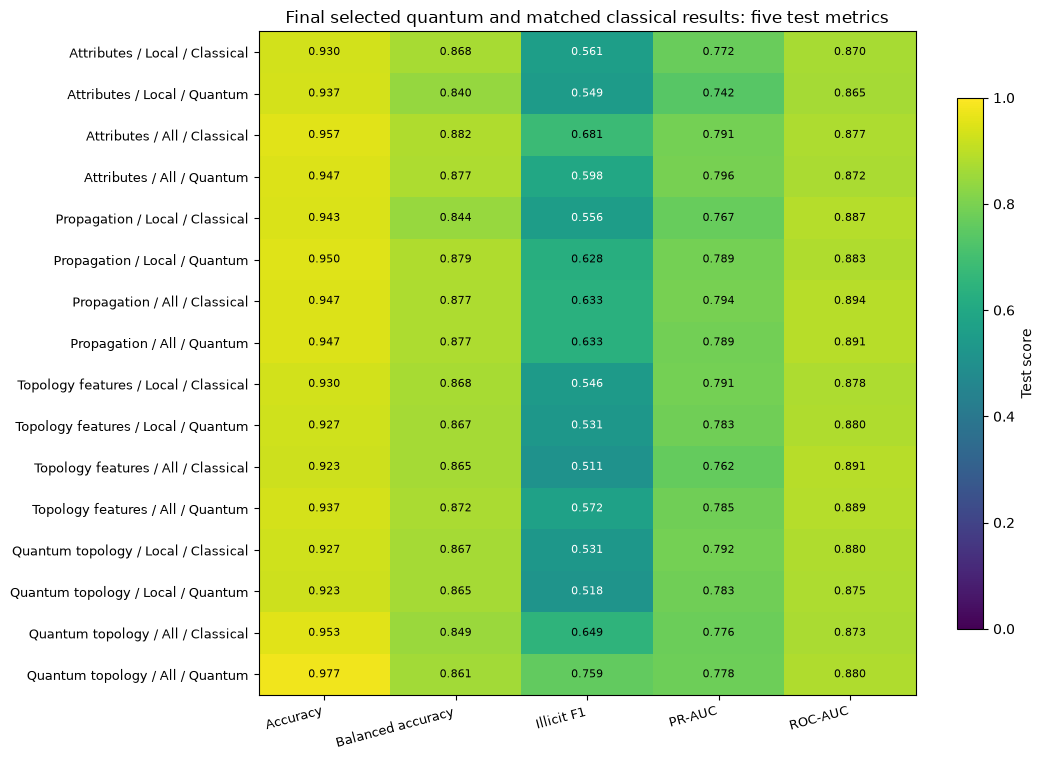

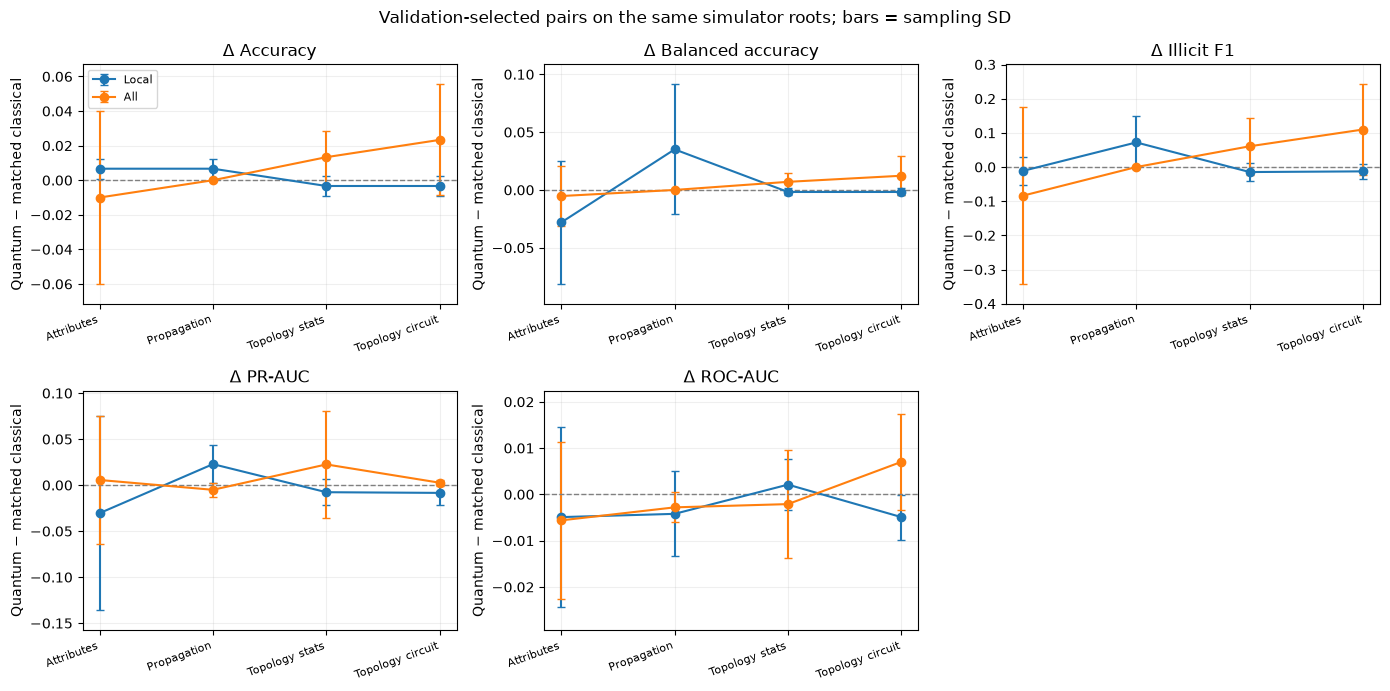

**Interpretation:** graph information, kernel choice and direct quantum topology are separate changes. Use paired differences to assess quantum value. The final QPU experiment establishes execution and noise/cost evidence; its small balanced classification scores do not establish quantum advantage. All full tables are in `results/experiment_flow/`.

In [14]:
flow.summary()